# Chaos and fractals 1: Chaos

*Learning path: chaos and fractals, part 1 of 2.* [Index](README.md) · Previous: [Simplify and eval](00-simplify-and-eval.ipynb) · Next: [Fractals](02-fractals.ipynb)

A rule can be completely fixed, with no randomness at all, and still produce behaviour that is impossible to predict.
This is **chaos**, found by Poincaré in the three-body problem around 1890 and rediscovered with computers in the 1960s
and 70s. You will learn

* how to follow a simple rule step by step with `iterate`,
* **fixed points**, and how the slope decides whether they attract or repel,
* the **logistic map** and its road to chaos by **period doubling**,
* the **bifurcation diagram**, and Feigenbaum's universal number,
* **sensitive dependence on initial conditions**: the butterfly effect in the Lorenz weather model.

You need the [foundations](../foundations/README.md) up to differential equations (lesson 8).

## 1. Following a rule

Take a population of insects, measured as a fraction $x$ of the most the habitat can hold (so $0 \le x \le 1$). Next
year's population grows with the number of insects but is held back by crowding:

$$x_{n+1} = r\,x_n(1 - x_n).$$

This is the **logistic map** (Robert May, 1976). The number $r$ is the growth rate, between 0 and 4.
`iterate(rule, x, x0, n)` lists $x_0, x_1, \ldots, x_n$: the starting value, then the rule applied again and again.
Here with $r = 2.5$, starting from $x_0 = 0.1$:

In [1]:
iterate(2.5*x*(1 - x), x, 0.1, 12)

[0.1, 0.225, 0.4359375, 0.614739990234375, 0.5920868366025388240814208984375, 0.6038000363113433, 0.5980638811544096, 0.6009586880323347, 0.5995183582769743, 0.6002402409146395, 0.5998797352534376, 0.600060096214258, 0.5999699428639835]

> `iterate`: x0, f(x0), f(f(x0)), ...

The population settles at $0.6$ and stays there. A value that the rule leaves unchanged is a **fixed point**. In
general $x = rx(1 - x)$ gives $x = 0$ or $x = 1 - 1/r$, which is $0.6$ for $r = 2.5$:

In [2]:
solve(x == 5/2*x*(1 - x), x)

[0, 3/5]

> Linear: x = −b/a = `3/5`.

### Attracting or repelling?

Near a fixed point $x^*$ the rule $f(x) = rx(1-x)$ is almost a straight line with slope $f'(x^*)$: the distance to the
fixed point gets multiplied by about $f'(x^*)$ each step. So the fixed point **attracts** when $|f'(x^*)| < 1$ and
**repels** when $|f'(x^*)| > 1$. At $x^* = 1 - 1/r$ the slope is $2 - r$:

In [3]:
f(x) := r*x*(1 - x);
simplify(subs(d(f, x), x, 1 - 1/r))

2-r

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

(`d(f, x)` is the derivative of the function `f` we just defined, and `subs` puts $x = 1 - 1/r$ into it.) So the fixed
point attracts for $1 < r < 3$ and repels for $r > 3$. What happens then?

## 2. The road to chaos

The plot shows the first 40 years for four growth rates: across is the year $n$, up is the population $x_n$. Each
series is a table with rows $[n, x_n]$, made from `iterate` (which gives the $x_n$ as a row) and the years
$0, 1, \ldots, 40$ (written `0:40`), stacked as two rows and turned into columns with `'`:

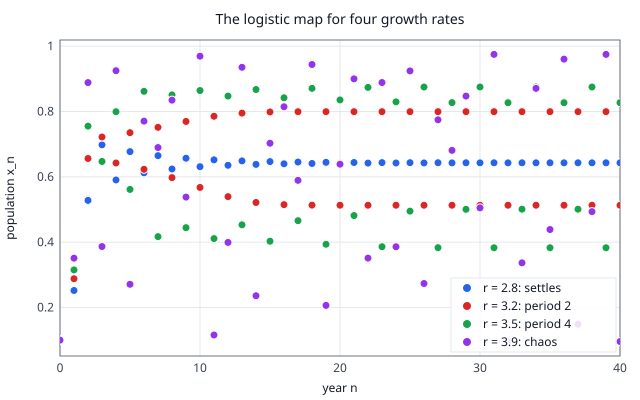

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
yrs = 0:40;
T(r) := [yrs; iterate(r*x*(1 - x), x, 0.1, 40)]';
p = show(scatter(T(2.8), [n x]), scatter(T(3.2), [n x]), scatter(T(3.5), [n x]), scatter(T(3.9), [n x]));
p = legend(p, "r = 2.8: settles", "r = 3.2: period 2", "r = 3.5: period 4", "r = 3.9: chaos");
labels(title(p, "The logistic map for four growth rates"), "year n", "population x_n")

* $r = 2.8$: the population settles down to one value (wobbling around it at first).
* $r = 3.2$: it alternates between two values forever, a cycle of **period 2**: good year, bad year.
* $r = 3.5$: a cycle of period 4.
* $r = 3.9$: no pattern at all. This is chaos.

The values after 60 years make it clearer. `iterate` returns a list, and `a(k)` picks its $k$-th entry, so
`[a(58) a(59) a(60) a(61)]` shows the years 57 to 60:

In [5]:
a = iterate(3.2*x*(1 - x), x, 0.1, 60);
[a(58) a(59) a(60) a(61)]
a = iterate(3.5*x*(1 - x), x, 0.1, 60);
[a(58) a(59) a(60) a(61)]

[0.7994554904673701, 0.5130445095326298, 0.7994554904673701, 0.5130445095326298]
[0.500884210307226, 0.8749972636024641, 0.38281968301732416, 0.8269407065914387]

## 3. The bifurcation diagram

To see all growth rates at once, for each $r$ run the map for a while until it has settled, then plot the next values
it visits. `orbitdata(rule, x, x0, r, r0, r1, nr, skip, keep)` does exactly that:

| argument | here | meaning |
|---|---|---|
| `rule` | `r*x*(1 - x)` | the map, in $x$ and the parameter $r$ |
| `x`, `x0` | `x`, `0.5` | the variable and its starting value |
| `r`, `r0`, `r1`, `nr` | `r`, `2.8`, `4`, `200` | the parameter, from 2.8 to 4 in 200 steps |
| `skip` | `500` | steps thrown away while the orbit settles |
| `keep` | `25` | steps kept and plotted |

It returns a table with one row $[r, x]$ per kept point (computed with decimals, which is fast). In the plot, across is
the growth rate $r$, up are the populations visited in the long run:

[5025, 2]

> `size` (see `trace`): Sum of the diagonal entries; size gives [rows columns].

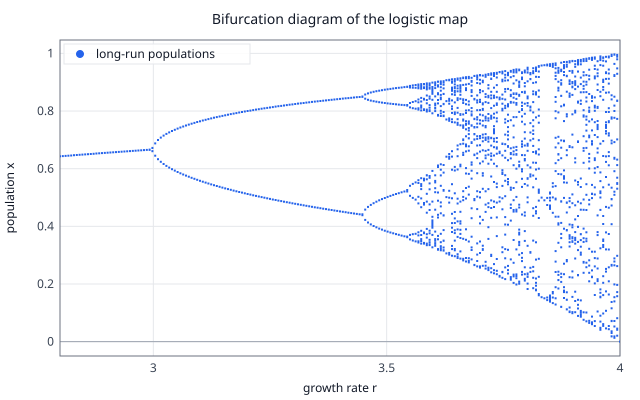

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
B = orbitdata(r*x*(1 - x), x, 0.5, r, 2.8, 4, 200, 500, 25);
size(B)
labels(title(legend(scatter(B, [r x]), "long-run populations"), "Bifurcation diagram of the logistic map"), "growth rate r", "population x")

Reading from left to right: one branch (a fixed point) until $r = 3$, where it splits in two (period 2), then in four at
$r \approx 3.449$, eight at $3.544$, and so on: **period doubling**. The splittings come faster and faster and pile up at
$r \approx 3.5699$; beyond that the dots fill whole intervals: chaos. Inside the chaos there are clear windows, like the
period-3 window near $r = 3.83$.

### Feigenbaum's constant

The distances between successive doublings shrink by a constant factor. With the doubling points
$r_1 = 3$, $r_2 = 1 + \sqrt6 \approx 3.449490$, $r_3 \approx 3.544090$, $r_4 \approx 3.564407$:

In [7]:
r1 = 3; r2 = 1 + sqrt(6); r3 = 3.544090; r4 = 3.564407;
eval((r2 - r1)/(r3 - r2))
eval((r3 - r2)/(r4 - r3))

4.751464277237159

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

4.656211902191382

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The ratios tend to $\delta = 4.669201\ldots$, the **Feigenbaum constant** (1978). The surprise: every map with one
smooth hump, not just the logistic map, gives the same $\delta$. It has been measured in dripping taps, convection in
liquid helium and electronic circuits.

## 4. Sensitive dependence

In the chaotic regime, two populations that start almost equal soon have nothing to do with each other. Start at
$x_0 = 0.2$ and at $x_0 = 0.2001$, with $r = 3.9$; the table lists the year, both populations and their difference:

In [8]:
a = iterate(3.9*x*(1 - x), x, 0.2, 30);
b = iterate(3.9*x*(1 - x), x, 0.2001, 30);
table([n, a(n + 1), b(n + 1), b(n + 1) - a(n + 1)], n, 0, 30)

[ 0,                               0.2,                0.2001,                 0.0001;
  1,                             0.624,           0.624233961,            0.000233961;
  2,                         0.9150336, 0.9148070994435768681, -0.0002265005564231319;
  3,                 0.303213732397056,    0.3039467739797055,  0.0007330415826494741;
  4, 0.8239731430433197995158138781696,    0.8250962170114376,   0.001123073968117838;
  5,                0.5656614700878674,    0.5628185537709237, -0.0028429163169436666;
  6,                0.9581854282490104,    0.9596099342783052,  0.0014245060292947809;
  7,                0.1562578420270566,   0.15115896241949867,  -0.005098879607557921;
  8,                0.5141811824452056,    0.5004087289490611,  -0.013772453496144532;
  9,                0.9742156868513775,    0.9749993484685201,  0.0007836616171426058;
 10,               0.09796598114189749,   0.09506491392247751, -0.0029010672194199755;
 11,                0.3446377259551312,    

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

The difference of $0.0001$ roughly doubles every year; after about 15 years the two runs are unrelated. To predict 15
years ahead you would need to know the start to 4 decimals, for 30 years to 8 decimals: long-term prediction is
impossible in practice, although the rule is exact.

### The Lorenz butterfly

In 1963 the meteorologist Edward Lorenz simplified a model of air convection to three equations for $x, y, z$:

$$x' = 10(y - x), \qquad y' = x(28 - z) - y, \qquad z' = xy - \tfrac83 z.$$

He restarted a computer run from printed numbers rounded to 3 decimals and found a completely different weather after
a while. `odeplot` (explained argument by argument in [foundations lesson 8](../foundations/08-differential-equations.ipynb))
draws two solutions from starts that differ by $0.001$ in $x$; across is the time $t$, up is $x(t)$:

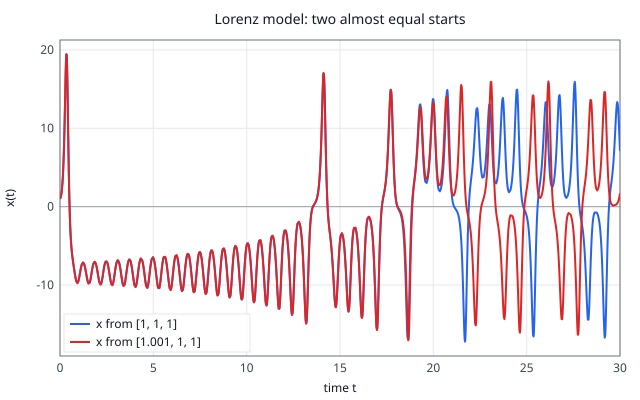

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
lor = [10*(y - x), x*(28 - z) - y, x*y - 8/3*z];
p = odeplot(lor, [x y z], t, [1 1 1; 1.001 1 1], 0, 30, [t x]);
labels(title(p, "Lorenz model: two almost equal starts"), "time t", "x(t)")

For about 20 time units the two curves are on top of each other; then they separate and never agree again. Lorenz's
1972 talk was titled "Does the flap of a butterfly's wings in Brazil set off a tornado in Texas?", which named the
**butterfly effect**. Weather forecasts are therefore run as ensembles of slightly different starts, and their spread
tells how far ahead the forecast can be trusted.

Plotted against each other, $x$ and $z$ trace the famous butterfly-shaped **strange attractor**, here from the first
start (across $x$, up $z$):

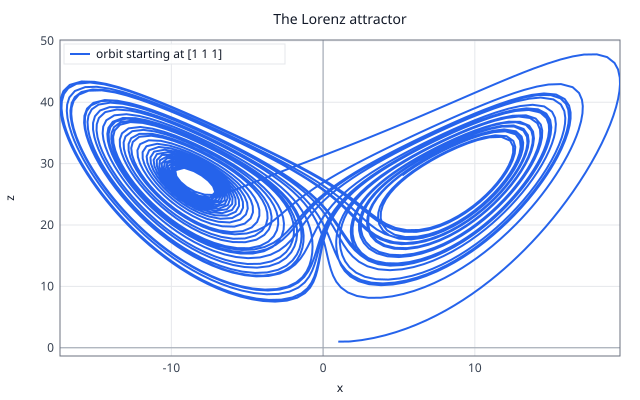

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
p = odeplot(lor, [x y z], t, [1 1 1], 0, 40, [x z]);
labels(title(legend(p, "orbit starting at [1 1 1]"), "The Lorenz attractor"), "x", "z")

The orbit loops around one wing, then the other, in an order that never repeats, yet always stays on the same
butterfly. Chaos is not disorder: it has a shape, and that shape is a fractal, the subject of the next lesson.

## Summary

* `iterate(rule, x, x0, n)` follows a rule step by step. Fixed points attract when $|f'(x^*)| < 1$.
* The logistic map $x \to rx(1-x)$: fixed point, then period 2, 4, 8, ... and chaos beyond $r \approx 3.57$.
* `orbitdata` builds a bifurcation diagram; the doublings shrink by Feigenbaum's $\delta \approx 4.669$.
* Chaos means sensitive dependence: tiny differences grow exponentially (the logistic map, the Lorenz model).

**Try it:** find the period-3 window in the bifurcation diagram by zooming in: `orbitdata` with $r$ from 3.82 to 3.86.
Check that the logistic map with $r = 4$ and $x_0 = \sin^2(\pi/7)$ cycles with period 3 (Hint: $x = \sin^2\theta$
becomes $\sin^2 2\theta$). Change the 28 in the Lorenz model to 10: is it still chaotic?

Next: [Fractals](02-fractals.ipynb).

## Sources

1. R. M. May, "Simple mathematical models with very complicated dynamics", *Nature* 261 (1976) 459–467.
2. M. J. Feigenbaum, "Quantitative universality for a class of nonlinear transformations", *J. Statistical Physics* 19 (1978) 25–52.
3. E. N. Lorenz, "Deterministic nonperiodic flow", *J. Atmospheric Sciences* 20 (1963) 130–141.
4. S. H. Strogatz, *Nonlinear Dynamics and Chaos*, 2nd ed., Westview Press (2015). Chapters 9 and 10.
5. J. Gleick, *Chaos: Making a New Science*, Viking (1987).